# Time-series forecasting with SAP-RPT-TS on SAP AI Core

**SAP-RPT-TS** (`sap-rpt-ts`) is SAP's pretrained time-series foundation model. You send the recent history of one or more series (sales per month, demand per day, ...) and it returns a forecast for the next steps, including a range of likely values. There is no training step: the model learns the pattern from the history you send in the request.

| Item | Value |
|---|---|
| AI Core deployment | scenario `foundation-models`, executable `aicore-sap`, model `sap-rpt-ts`, version `1` |
| Endpoint | `POST {deployment_url}/predict` |
| History per series | up to 8,192 time steps (older steps are cut off) |
| Forecast length (horizon) | up to 1,024 steps |
| Targets + covariates | keep below 128 per series |

The SAP AI SDK has no client for this model yet, so this notebook uses `rpt_ts_client.py`, a thin wrapper around `rpt_client_api.py` that handles authentication and finds the running `sap-rpt-ts` deployment.

Contents:

1. How a forecast request is built: target, timestamps, past and future covariates.
2. How to read the response.
3. Deterministic rules: overriding the forecast for known situations.
4. Real data: 20 years of hotel nights in 13 Swiss tourism regions.
5. Testing forecast quality properly with a rolling backtest.
6. Ranges and quantiles, and which single number to use (`point_forecast`).
7. Hierarchical forecasting: numbers that add up.

## 1. Setup

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import find_dotenv, load_dotenv
from tqdm.auto import tqdm

from rpt_client_api import RPTAPIError
from rpt_ts_client import RPTTSClientAPI, forecast_to_frame, hierarchy_to_frame

_ = load_dotenv(find_dotenv(usecwd=True))
client = RPTTSClientAPI()  # finds the running sap-rpt-ts deployment
pd.set_option("display.width", 160)

## 2. How a forecast request is built

Think of one time series as a timeline split in two parts:

```
               history (known)                       |   horizon (to forecast)
 time step:    t1     t2     t3     t4     t5     t6  |   t7     t8     t9
 target:       120    135    128    142    150    149 |   ?      ?      ?
 temperature:  15     18     17     21     24     26  |   27     25     22    <- known in advance (weather forecast)
 promotion:    0      1      0      0      1      0   |   1      0      0     <- planned in advance
 web visits:   900    1100   950    990    1200   1150|   (not known)         <- only measured afterwards
```

| Field | What it is | Length | Required |
|---|---|---|---|
| `target` | The values you want to forecast (here monthly sales), one per past time step. `null` marks a missing value. | number of history steps | yes |
| `timestamp` | The date or time of each target value. Steps should be evenly spaced (every day, every month, ...). A few gaps are allowed (at most 20% filled in). Without timestamps the forecast has no dates. | same as `target` | no |
| `past_covariates` | Other variables measured at the same past steps that may explain the target (temperature, promotions, prices, web visits). Numbers or text. | same as `target` | no |
| `future_covariates` | The values of covariates for the forecast steps, for variables you **know in advance** (planned promotions, holidays, weather forecasts). Every future covariate must also appear in `past_covariates`: the model learns from the past how the variable relates to the target, then applies that to the future values. | `horizon` | no |
| `horizon` (top level) | How many steps to forecast. | - | yes |

So in the example, `temperature` and `promotion` are both past and future covariates. `web visits` can only be a past covariate: it helps the model understand the history, but its future values are unknown.

Accepted timestamp formats: integers, `YYYY-MM-DD`, `YYYY-MM-DD HH:MM:SS`, `YYYY-MM-DD HH:MM:SS.fffffff` and `HH:MM:SS`. Timestamps are read as written, without time zone conversion.

The cell below writes that example as a table (illustrative numbers) and turns it into a request, so you can see how each column maps to a field.

In [2]:
example = pd.DataFrame({
    "timestamp": pd.date_range("2024-01-01", periods=9, freq="MS").strftime("%Y-%m-%d"),
    "target": [120, 135, 128, 142, 150, 149, None, None, None],
    "temperature": [15, 18, 17, 21, 24, 26, 27, 25, 22],
    "promotion": [0, 1, 0, 0, 1, 0, 1, 0, 0],
    "web_visits": [900, 1100, 950, 990, 1200, 1150, None, None, None],
})
HORIZON_EXAMPLE = 3
history, future = example.iloc[:-HORIZON_EXAMPLE], example.iloc[-HORIZON_EXAMPLE:]

example_request = {
    "horizon": HORIZON_EXAMPLE,
    "data": [  # one entry per series; here a single series
        {
            "timestamp": history["timestamp"].tolist(),
            "target": history["target"].tolist(),
            "past_covariates": {
                "temperature": history["temperature"].tolist(),
                "promotion": history["promotion"].tolist(),
                "web_visits": history["web_visits"].tolist(),
            },
            "future_covariates": {
                "temperature": future["temperature"].tolist(),
                "promotion": future["promotion"].tolist(),
            },
        }
    ],
    "options": {"confidence_interval": 0.8},
}
print(json.dumps(example_request, indent=2))

{
  "horizon": 3,
  "data": [
    {
      "timestamp": [
        "2024-01-01",
        "2024-02-01",
        "2024-03-01",
        "2024-04-01",
        "2024-05-01",
        "2024-06-01"
      ],
      "target": [
        120.0,
        135.0,
        128.0,
        142.0,
        150.0,
        149.0
      ],
      "past_covariates": {
        "temperature": [
          15,
          18,
          17,
          21,
          24,
          26
        ],
        "promotion": [
          0,
          1,
          0,
          0,
          1,
          0
        ],
        "web_visits": [
          900.0,
          1100.0,
          950.0,
          990.0,
          1200.0,
          1150.0
        ]
      },
      "future_covariates": {
        "temperature": [
          27,
          25,
          22
        ],
        "promotion": [
          1,
          0,
          0
        ]
      }
    }
  ],
  "options": {
    "confidence_interval": 0.8
  }
}


**Several series in one request.** `data` is a list: add one entry per series (for example one per product or store). Each series has its own timestamps, target and covariates and can have a different length. They are forecast independently unless `options.cross_learning` is `true` (section 5).

**Several targets in one series.** If two values share the same timeline and covariates (for example units sold and revenue), pass `target` as a list of lists: `[[120, 135, ...], [1200, 1350, ...]]`. All inner lists must have the same length.

## 3. How to read the response

In [3]:
example_response = client.forecast(example_request)
print(json.dumps(example_response, indent=2))

{
  "all_null_targets": [],
  "confidence_interval_output": [
    [
      [
        [
          143.70480346679688,
          138.6031951904297,
          134.7220001220703
        ],
        [
          164.86367797851562,
          162.73291015625,
          163.80836486816406
        ]
      ]
    ]
  ],
  "detected_interval": [
    {
      "unit": "month",
      "value": 1
    }
  ],
  "group_results": null,
  "hierarchical_result": null,
  "quantile_result": null,
  "result": [
    [
      [
        153.8961181640625,
        150.3931884765625,
        148.6690673828125
      ]
    ]
  ],
  "result_timestamp": [
    [
      "2024-07-01",
      "2024-08-01",
      "2024-09-01"
    ]
  ],
  "selected_quantile_result": null,
  "usage": {
    "input_time_points": 30,
    "output_time_points": 3
  }
}


The arrays are nested **series, then target, then forecast step**. For the first series and its first target:

| Field | Meaning | Here |
|---|---|---|
| `result[0][0]` | the forecast, one value per future step | 3 values |
| `confidence_interval_output[0][0][0]` / `[0][0][1]` | lower and upper end of the likely range (80% unless set otherwise, section 6) | 3 + 3 values |
| `result_timestamp[0]` | dates of the forecast steps | `2024-07-01`... |
| `detected_interval[0]` | the spacing the model read from your timestamps | 1 month |
| `quantile_result`, `selected_quantile_result`, `hierarchical_result` | only filled when requested (sections 6 and 7) | `null` |
| `all_null_targets` | series or targets whose history was entirely empty | `[]` |
| `usage` | time points read and produced; this is what is billed | |

`forecast_to_frame` turns the nested arrays into one row per series, target and step:

In [4]:
example_forecast = forecast_to_frame(example_response, series_ids=["sales"])
example_forecast

,series,variate,step,timestamp,point,lower,upper
0,sales,0,1,2024-07-01,153.896118,143.704803,164.863678
1,sales,0,2,2024-08-01,150.393188,138.603195,162.732910
2,sales,0,3,2024-09-01,148.669067,134.722000,163.808365


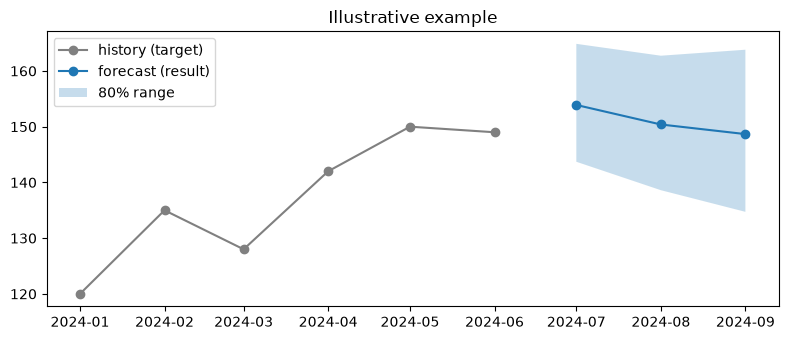

In [5]:
fig, axis = plt.subplots(figsize=(8, 3.5))
axis.plot(pd.to_datetime(history["timestamp"]), history["target"], marker="o", color="grey", label="history (target)")
dates = pd.to_datetime(example_forecast["timestamp"])
axis.plot(dates, example_forecast["point"], marker="o", color="tab:blue", label="forecast (result)")
axis.fill_between(dates, example_forecast["lower"], example_forecast["upper"], alpha=0.25, label="80% range")
axis.legend()
axis.set_title("Illustrative example")
plt.tight_layout()

**Errors.** The service checks the request and answers HTTP 400 or 422 with a message naming the problem. The client raises it as `RPTAPIError`. Example: a future covariate with 2 values while the horizon is 3.

In [6]:
broken = json.loads(json.dumps(example_request))
broken["data"][0]["future_covariates"]["temperature"] = [27, 25]
try:
    client.forecast(broken)
except RPTAPIError as error:
    print("HTTP", error.http_status, "->", str(error)[:300])

HTTP 400 -> RPT-TS /predict failed with HTTP 400: future_covariates.temperature length must match horizon


## 4. Deterministic rules

Sometimes you know the answer for certain steps regardless of history: a store sells nothing on days it is closed, a machine produces nothing during planned maintenance. **Rules** set the forecast to a fixed value whenever a future covariate meets a condition.

Rules go into `options.rules` as a list. Each rule is an object with four fields:

```json
"options": {
  "rules": [
    {"covariate": "closed", "operator": "==", "threshold": 1, "forecast_value": 0}
  ]
}
```

| Field | Type | Meaning |
|---|---|---|
| `covariate` | text | Name of a **future covariate**. It must be numeric and exist in `future_covariates` of **every** series in the request (otherwise HTTP 400). |
| `operator` | text | How the covariate value is compared with `threshold`: `==`, `!=`, `>`, `>=`, `<`, `<=`. |
| `threshold` | number | The value to compare with. |
| `forecast_value` | number | The forecast to use for every step where the condition is true. |

How the service applies them (checked with live requests):

1. For each forecast step, it reads that step's value of the covariate and tests `value <operator> threshold`.
2. If the test is true, the forecast of that step becomes `forecast_value`, for all targets of the series.
3. Rules are applied in list order; if several match the same step, **the last one wins**.
4. Only the forecast (`result`) changes. The range (`confidence_interval_output`) and quantiles are not adjusted, so a rule value can lie outside the reported range.

The example below uses two rules: "closed means zero" and "a promotion at level 2 or higher means 300". In step 2 both conditions are true, so the order decides.

In [7]:
rules_series = {
    "timestamp": history["timestamp"].tolist(),
    "target": history["target"].tolist(),
    "past_covariates": {"closed": [0, 0, 0, 0, 0, 0], "promotion": [0, 1, 0, 0, 1, 0]},
    "future_covariates": {"closed": [0, 1, 1], "promotion": [0, 2, 0]},
}
closed_rule = {"covariate": "closed", "operator": "==", "threshold": 1, "forecast_value": 0}
promotion_rule = {"covariate": "promotion", "operator": ">=", "threshold": 2, "forecast_value": 300}

steps = pd.DataFrame({"closed": rules_series["future_covariates"]["closed"],
                      "promotion": rules_series["future_covariates"]["promotion"]},
                     index=["step 1", "step 2", "step 3"])
for name, rules in {"no rules": [], "closed": [closed_rule],
                    "closed, then promotion": [closed_rule, promotion_rule],
                    "promotion, then closed": [promotion_rule, closed_rule]}.items():
    response = client.forecast({"horizon": 3, "data": [rules_series], "options": {"rules": rules}})
    steps[name] = np.round(response["result"][0][0], 1)
steps

,closed,promotion,no rules,"closed, then promotion","promotion, then closed"
step 1,151.9,0,151.9,151.9,151.9
step 2,0.0,2,160.2,300.0,0.0
step 3,0.0,0,158.9,0.0,0.0


Reading the table: without rules the model forecasts its usual values. With the closed rule, steps 2 and 3 (closed = 1) become 0. With both rules, step 2 matches both, and the rule listed last decides (300 or 0).

## 5. Real data: hotel nights in Switzerland, 2005 to 2026

`data/hotel_nights_2005_2026.csv` comes from the Swiss Federal Statistical Office (FSO) hotel accommodation statistics (HESTA), table px-x-1003020000_103, downloaded through the FSO PxWeb API. Each row is the number of **overnight stays** (one guest spending one night in a hotel) in one month, for:

| Column | Meaning |
|---|---|
| `MONTH` | first day of the month, January 2005 to August 2026 (260 months) |
| `REGION` | one of the 13 Swiss tourism regions |
| `GUEST_ORIGIN` | where the guests live: Switzerland, Germany, France, Italy, Austria, Netherlands, Spain, or `Other countries` (the region's total minus these seven) |
| `OVERNIGHT_STAYS` | number of nights |

Adding up the guest origins gives **the total hotel nights per month in each region**: 13 series with more than 20 years of history. The region x origin rows (104 series) are used in sections 6 and 8. The FSO notes that some region boundaries were adjusted in 2017, 2020 and 2022; the series are used as published.

Source: Swiss Federal Statistical Office, HESTA, table px-x-1003020000_103. Open use; the source must be cited.

In [8]:
hotel = pd.read_csv("data/hotel_nights_2005_2026.csv")
origins = hotel.pivot_table(index=["REGION", "GUEST_ORIGIN"], columns="MONTH", values="OVERNIGHT_STAYS").astype(float)
regions = origins.groupby(level="REGION").sum()
months = pd.to_datetime(regions.columns)
regions.columns = origins.columns = months

recent = regions.loc[:, "2023-01-01":"2025-12-01"]  # three normal years, after the pandemic
by_month = recent.T.groupby(recent.columns.month).mean()
profile = pd.DataFrame({
    "average nights per month (2023-2025)": recent.mean(axis=1).round(-2),
    "busiest month": by_month.idxmax().map(lambda m: pd.Timestamp(2024, m, 1).strftime("%B")),
    "quietest month": by_month.idxmin().map(lambda m: pd.Timestamp(2024, m, 1).strftime("%B")),
}).sort_values("average nights per month (2023-2025)", ascending=False)
print(f"{len(regions)} regional series and {len(origins)} region x origin series, "
      f"{len(months)} months ({months[0]:%b %Y} to {months[-1]:%b %Y})")
profile

13 regional series and 104 region x origin series, 260 months (Jan 2005 to Aug 2026)


,average nights per month (2023-2025),busiest month,quietest month
REGION,,,
Zurich Region,606100.0,July,February
Bern Region,506600.0,July,November
Graubünden,462000.0,February,November
Valais,373500.0,February,November
Lucerne / Lake Lucerne,339300.0,July,November
Geneva,310900.0,July,February
Vaud,249200.0,July,January
Ticino,205200.0,July,January
Eastern Switzerland,169600.0,August,January


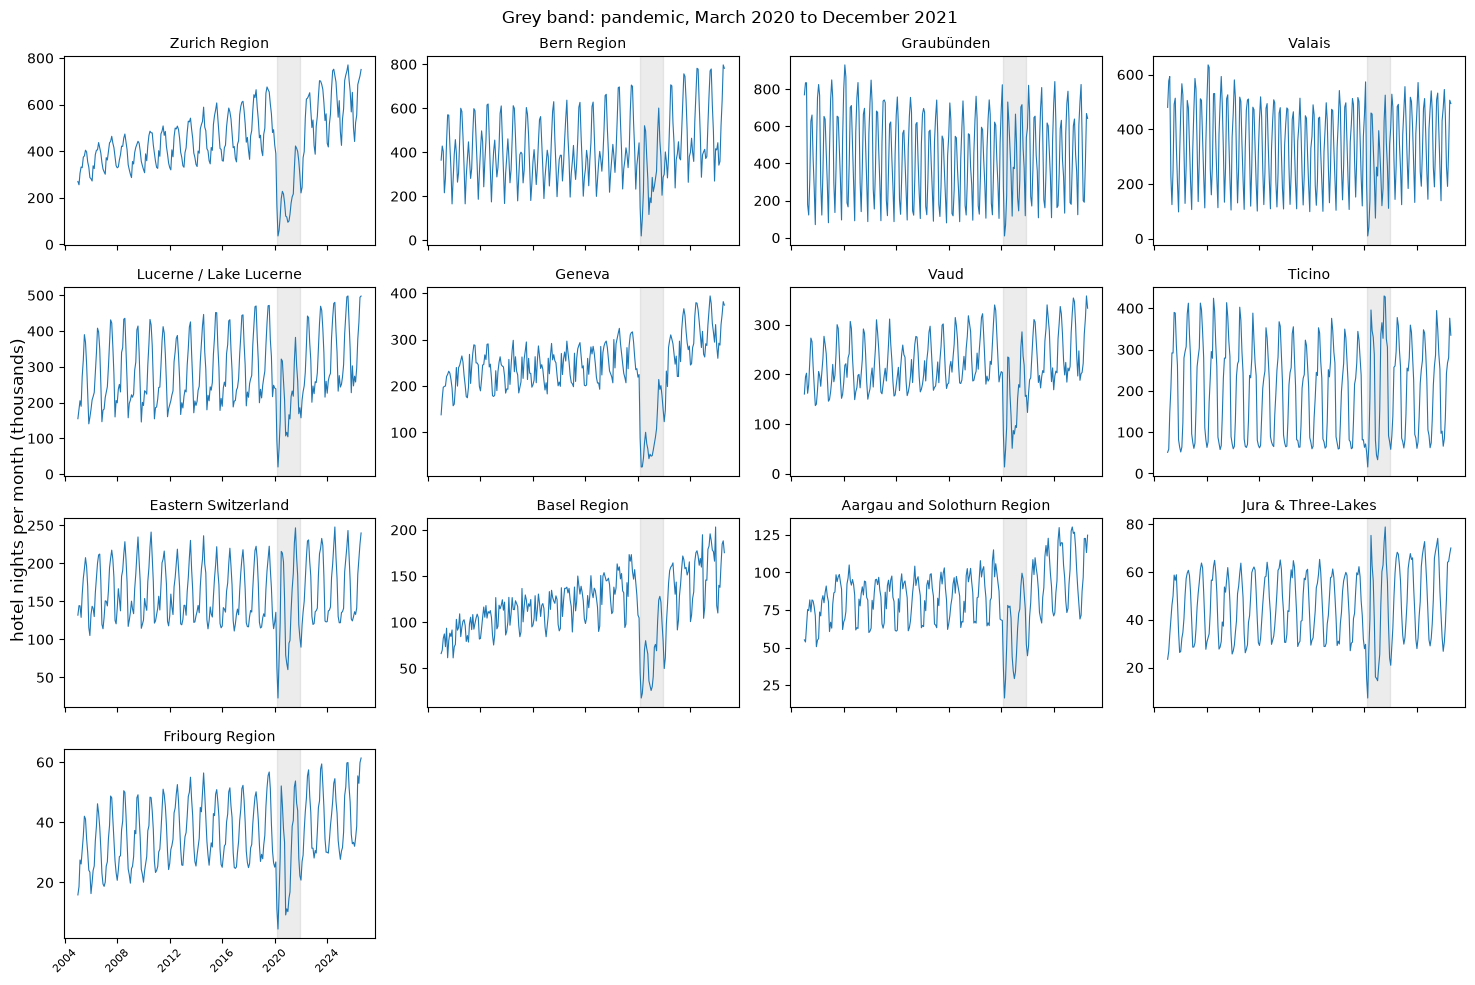

In [9]:
fig, axes = plt.subplots(4, 4, figsize=(15, 10), sharex=True)
for axis, region in zip(axes.flat, profile.index):
    axis.plot(months, regions.loc[region] / 1e3, color="tab:blue", linewidth=0.8)
    axis.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"), color="grey", alpha=0.15)
    axis.set_title(region, fontsize=10)
    axis.tick_params(axis="x", rotation=45, labelsize=8)
for axis in axes.flat[len(profile):]:
    axis.axis("off")
fig.supylabel("hotel nights per month (thousands)")
fig.suptitle("Grey band: pandemic, March 2020 to December 2021")
plt.tight_layout()

Every region repeats a strong yearly pattern: the Alpine regions Graubünden and Valais are busiest in February (ski season), most others in summer. The pandemic (grey band) cut the city regions such as Zurich and Geneva much more than the mountain regions. A forecasting model has to cope with such breaks in the history.

## 6. Testing forecast quality with a rolling backtest

To judge a forecast you compare it with what really happened. A **backtest** pretends to be in the past: take the data up to a cut-off month, forecast the following months, and compare with the actual values.

One cut-off alone gives only a few numbers per series and can be good or bad by luck. A **rolling backtest** repeats this for many cut-offs. Here: **24 cut-offs**; the first forecast starts in July 2024, the last in June 2026. For each cut-off we forecast the next 3 months of all 13 regions, which gives 312 comparisons for "1 month ahead" and 312 for "3 months ahead".

**Baseline.** A forecast is only useful if it beats a simple rule. For seasonal data the standard rule is **seasonal naive**: "a month will be like the same month last year".

**Real covariate.** "Same month last year" is also known in advance for any month up to a year ahead, so it can be passed as a past and future covariate (`last_year`). For the first year of history it is unknown and sent as `null`.

**Few requests.** Each (cut-off, series) pair is sent as its own series, so a whole backtest takes a few requests. This only works while `cross_learning` is off: with cross-learning the model learns across all series of the request, and the later cut-offs contain the future of the earlier ones.

In [10]:
FIRST_FORECAST = months.get_loc(pd.Timestamp("2024-07-01"))
CUTOFFS = list(range(FIRST_FORECAST, FIRST_FORECAST + 24))  # history = months[:cutoff]


def make_series(table, key, cutoff, horizon, with_last_year=False, history_months=None):
    '''History of one series up to `cutoff` (exclusive), optionally shortened and with the last_year covariate.'''
    start = 0 if history_months is None else cutoff - history_months
    values = table.loc[key]
    series = {"timestamp": [m.strftime("%Y-%m-%d") for m in months[start:cutoff]],
              "target": values.iloc[start:cutoff].tolist()}
    if with_last_year:
        lagged = values.shift(12)
        series["past_covariates"] = {"last_year": [None if np.isnan(v) else v for v in lagged.iloc[start:cutoff]]}
        series["future_covariates"] = {"last_year": lagged.iloc[cutoff:cutoff + horizon].tolist()}
    return series


def rolling_backtest(table, cutoffs, horizon=3, with_last_year=False, history_months=None, options=None, chunk=100):
    '''Forecast `horizon` months after every cut-off for every series of `table`; one row per forecast step.'''
    keys = [(cutoff, key) for cutoff in cutoffs for key in table.index]
    frames = []
    for start in range(0, len(keys), chunk):
        part = keys[start:start + chunk]
        response = client.forecast({
            "horizon": horizon,
            "data": [make_series(table, key, cutoff, horizon, with_last_year, history_months) for cutoff, key in part],
            "options": {"clip_min": 0, "confidence_interval": 0.8, **(options or {})},
        }, compress=True)
        frame = forecast_to_frame(response)
        frame["cutoff"] = [part[s][0] for s in frame["series"]]
        frame["key"] = [part[s][1] for s in frame["series"]]
        frames.append(frame)
    frame = pd.concat(frames, ignore_index=True)
    position = frame["cutoff"] + frame["step"] - 1
    frame["month"] = months[position]
    frame["actual"] = [table.loc[k].iloc[p] for k, p in zip(frame["key"], position)]
    frame["seasonal_naive"] = [table.loc[k].iloc[p - 12] for k, p in zip(frame["key"], position)]
    return frame


def score(frame, step):
    '''Accuracy at one forecast step (1 = next month) for the model and the seasonal-naive baseline.'''
    part = frame[frame["step"] == step]
    def mape(predicted):
        return (np.abs(predicted - part["actual"]) / part["actual"]).mean()
    def wape(predicted):
        return np.abs(predicted - part["actual"]).sum() / part["actual"].sum()
    return {
        "comparisons": len(part),
        "MAPE model": mape(part["point"]), "MAPE seasonal naive": mape(part["seasonal_naive"]),
        "WAPE model": wape(part["point"]), "WAPE seasonal naive": wape(part["seasonal_naive"]),
        "80% range hit rate": ((part["actual"] >= part["lower"]) & (part["actual"] <= part["upper"])).mean(),
    }

Variants on the 13 regional series:

* **full history**: all months before the cut-off (about 20 years), target and timestamps only;
* **full history + last_year**: with the "same month last year" covariate;
* **full history + last_year, enhanced**: `options.enhanced_forecast = true`, extra inference passes for accuracy; input time points are billed at 4x;
* **last 24 months only**: the same request, but only the 24 months before the cut-off, to see how much the long history matters.

Metrics:

* **MAPE** (mean absolute percentage error): the average forecast error as a share of the actual value; 0.05 means "5% off on average". Lower is better.
* **WAPE** (weighted absolute percentage error): all errors added up, divided by all actual nights added up. Large series count more; it is the better choice when some series are small, because a small series with 30 instead of 10 nights would count as "200% off" in MAPE.
* **80% range hit rate**: how often the actual value fell inside the 80% range. Close to 0.80 means the range is well sized; much higher means it is wider than needed.

In [11]:
variants = {
    "full history": dict(),
    "full history + last_year": dict(with_last_year=True),
    "full history + last_year, enhanced": dict(with_last_year=True, options={"enhanced_forecast": True}),
    "last 24 months only": dict(history_months=24),
}
backtests, rows = {}, []
for name, settings in tqdm(variants.items(), desc="backtests"):
    backtests[name] = rolling_backtest(regions, CUTOFFS, **settings)
    for step in (1, 3):
        rows.append({"variant": name, "months ahead": step, **score(backtests[name], step)})
pd.DataFrame(rows).set_index(["months ahead", "variant"]).sort_index().round(3)

backtests:   0%|          | 0/4 [00:00<?, ?it/s]

comparisons  MAPE model  MAPE seasonal naive  WAPE model  WAPE seasonal naive  80% range hit rate
months ahead variant                                                                                                                              
1            full history                                312       0.046                0.047       0.043                0.043               0.840
             full history + last_year                    312       0.045                0.047       0.043                0.043               0.833
             full history + last_year, enhanced          312       0.044                0.047       0.041                0.043               0.853
             last 24 months only                         312       0.058                0.047       0.057                0.043               0.885
3            full history                                312       0.050                0.046       0.047                0.042               0.833
             full history + last_year                    312       0.049                0.046       0.048                0.042               0.846
             full history + last_year, enhanced          312       0.048                0.046       0.047                0.042               0.859
             last 24 months only                         312       0.052                0.046       0.048                0.042               0.936

**Cross-learning.** `options.cross_learning = true` lets the model learn across all series of one request, which can help when the series are related (regions of one country). Because of the leakage issue above, it is tested with one request per cut-off (every second cut-off, to keep the number of requests small).

In [12]:
cross_rows = []
for cutoff in tqdm(CUTOFFS[::2], desc="cut-offs"):
    for cross in (False, True):
        response = client.forecast({
            "horizon": 3,
            "data": [make_series(regions, region, cutoff, 3, with_last_year=True) for region in regions.index],
            "options": {"clip_min": 0, "cross_learning": cross},
        })
        for region, series in zip(regions.index, response["result"]):
            for step in (0, 2):
                actual = regions.loc[region].iloc[cutoff + step]
                cross_rows.append({"cross_learning": cross, "months ahead": step + 1,
                                   "ape": abs(series[0][step] - actual) / actual})
pd.DataFrame(cross_rows).pivot_table(index="cross_learning", columns="months ahead", values="ape").round(3).add_prefix("MAPE, months ahead = ")

cut-offs:   0%|          | 0/12 [00:00<?, ?it/s]

months ahead,"MAPE, months ahead = 1","MAPE, months ahead = 3"
cross_learning,,
False,0.043,0.049
True,0.043,0.049


### Where the model pays off: noisier series

The regional totals follow the yearly pattern so closely that "same month last year" is already a very good forecast. The region x guest-origin series (for example German guests in Ticino) move more from year to year. Same backtest on those 104 series (every second cut-off, 1,248 forecasts), measured with WAPE:

In [13]:
origin_rows = []
for name, settings in tqdm({"no covariates": dict(), "+ last_year": dict(with_last_year=True)}.items(), desc="backtests"):
    frame = rolling_backtest(origins, CUTOFFS[::2], **settings)
    for step in (1, 3):
        result = score(frame, step)
        origin_rows.append({"variant": name, "months ahead": step, "comparisons": result["comparisons"],
                            "WAPE model": result["WAPE model"], "WAPE seasonal naive": result["WAPE seasonal naive"],
                            "80% range hit rate": result["80% range hit rate"]})
pd.DataFrame(origin_rows).set_index(["months ahead", "variant"]).sort_index().round(3)

backtests:   0%|          | 0/2 [00:00<?, ?it/s]

comparisons  WAPE model  WAPE seasonal naive  80% range hit rate
months ahead variant                                                                        
1            + last_year           1248       0.058                0.063               0.837
             no covariates         1248       0.064                0.063               0.808
3            + last_year           1248       0.064                0.062               0.841
             no covariates         1248       0.066                0.062               0.836

### What the backtest shows

Read the tables above together with these points (numbers from our run):

* **Regional totals.** With the full history the model is about as accurate as the seasonal-naive rule: one month ahead 4.4-4.6% average error against 4.7%, three months ahead 4.8-5.0% against 4.6%. The yearly pattern of these totals is so regular that "same month last year" is very hard to beat.
* **Long history matters.** With only the last 24 months the error one month ahead rises to 5.8%, and the ranges become wider than needed (hit rate 0.89-0.94 instead of about 0.84).
* **Ranges are well sized** with the full history: the 80% range contained the actual value in 83-86% of the cases.
* `last_year` and `enhanced_forecast` gave small gains (best one month ahead: 4.4%, at four times the billed input points). `cross_learning` made no difference on these series.
* **Noisier series are where the model pays off.** On the region x guest-origin series the model with the `last_year` covariate beat seasonal naive one month ahead (WAPE 5.8% against 6.3%) and was close three months ahead (6.4% against 6.2%).
* Always backtest over many cut-offs: single months can make any method look better or worse than it is.

The plot shows every one-month-ahead forecast of the "full history + last_year" variant (24 per region) against the actual values, with the history since 2022 for context.

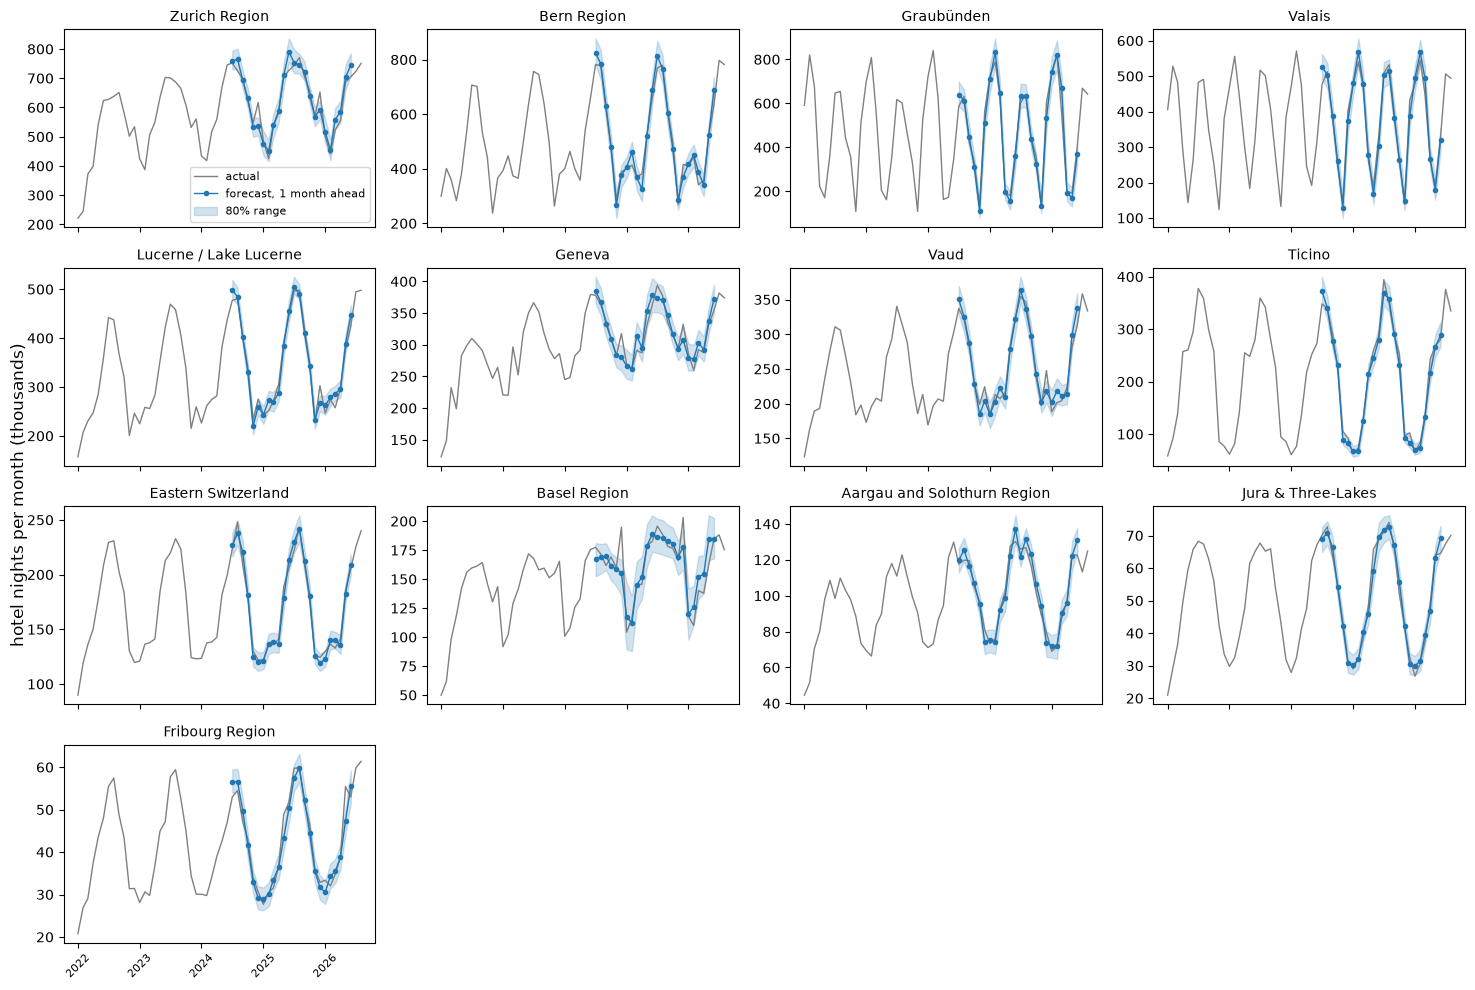

In [14]:
one_ahead = backtests["full history + last_year"].query("step == 1")
shown = months >= pd.Timestamp("2022-01-01")
fig, axes = plt.subplots(4, 4, figsize=(15, 10), sharex=True)
for axis, region in zip(axes.flat, profile.index):
    part = one_ahead[one_ahead["key"] == region]
    axis.plot(months[shown], regions.loc[region][shown] / 1e3, color="grey", linewidth=1, label="actual")
    axis.plot(part["month"], part["point"] / 1e3, marker="o", markersize=3, color="tab:blue", linewidth=1, label="forecast, 1 month ahead")
    axis.fill_between(part["month"], part["lower"] / 1e3, part["upper"] / 1e3, alpha=0.2, color="tab:blue", label="80% range")
    axis.set_title(region, fontsize=10)
    axis.tick_params(axis="x", rotation=45, labelsize=8)
for axis in axes.flat[len(profile):]:
    axis.axis("off")
axes.flat[0].legend(fontsize=8)
fig.supylabel("hotel nights per month (thousands)")
plt.tight_layout()

## 7. Ranges, quantiles and the single forecast number

### Why a range

The future is uncertain, so the model does not compute one number: it estimates **how likely each possible outcome is**. The response summarizes that uncertainty in two ways.

**Quantiles.** A quantile is a value with a probability attached:

* the **0.1 quantile** is a value the actual result should fall *below* in about 1 out of 10 cases (a cautious low estimate);
* the **0.5 quantile** (the median) is the middle: the actual result is equally likely to be above or below it;
* the **0.9 quantile** is a value the actual result should exceed in only about 1 out of 10 cases (a high estimate).

**Ranges (confidence intervals).** A range is the space between two quantiles. The 80% range goes from the 0.1 to the 0.9 quantile, so about 8 out of 10 actual values should land inside it. That is what `options.confidence_interval` controls (default 0.8; `0.9` returns the 0.05 to 0.95 quantiles; `null` switches it off).

Typical uses: plan capacity with the 0.9 quantile so you rarely run short, budget conservatively with the 0.1 quantile, and report the median as the expected value.

### Requesting quantiles

| Option | Returns |
|---|---|
| `"quantile_levels": [0.1, 0.5, 0.9]` | only those quantiles, in `selected_quantile_result[series][target][quantile][step]` |
| `"output_quantile": true` | the full fixed set of 21 quantiles (0.01, 0.05, 0.10, ..., 0.95, 0.99) in `quantile_result[series][target][21][step]` |

Example: forecast of March to May 2026 for Graubünden, from the history up to February 2026.

In [15]:
CUTOFF_EXAMPLE = months.get_loc(pd.Timestamp("2026-03-01"))  # history up to February 2026
quantile_response = client.forecast({
    "horizon": 3,
    "data": [make_series(regions, "Graubünden", CUTOFF_EXAMPLE, 3, with_last_year=True)],
    "options": {"quantile_levels": [0.1, 0.5, 0.9], "output_quantile": True, "confidence_interval": None},
})
print("selected_quantile_result shape:", np.array(quantile_response["selected_quantile_result"]).shape)
print("quantile_result shape:", np.array(quantile_response["quantile_result"]).shape)

future_months = quantile_response["result_timestamp"][0]
selected = np.array(quantile_response["selected_quantile_result"])[0, 0]
pd.DataFrame({
    "low (q0.1)": selected[0],
    "median (q0.5)": selected[1],
    "high (q0.9)": selected[2],
    "actual": regions.loc["Graubünden"].iloc[CUTOFF_EXAMPLE:CUTOFF_EXAMPLE + 3].to_numpy(),
}, index=future_months).round(-2)

selected_quantile_result shape: (1, 1, 3, 3)
quantile_result shape: (1, 1, 21, 3)


,low (q0.1),median (q0.5),high (q0.9),actual
2026-03-01,612200.0,668300.0,722200.0,549600.0
2026-04-01,162300.0,199000.0,243300.0,199100.0
2026-05-01,137600.0,174400.0,217000.0,191200.0


In March 2026 the actual value fell below the low estimate. With a 0.1 quantile that should happen in about 1 of 10 cases, so one month says little; the backtest hit rate in section 6 is the reliable check.

The full set of 21 quantiles can be drawn as a "fan": the darker the band, the more likely the outcome.

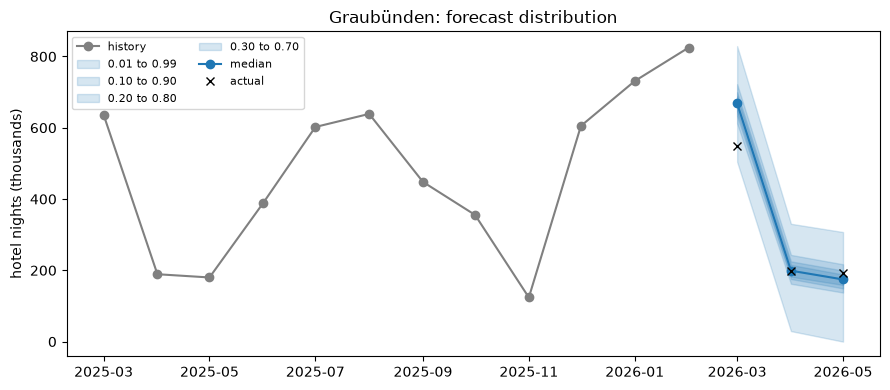

In [16]:
LEVELS = [0.01, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50,
          0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.99]
grid = np.array(quantile_response["quantile_result"])[0, 0] / 1e3  # [21 quantiles][3 steps]
dates = pd.to_datetime(future_months)
history_shown = slice(CUTOFF_EXAMPLE - 12, CUTOFF_EXAMPLE)
fig, axis = plt.subplots(figsize=(9, 4))
axis.plot(months[history_shown], regions.loc["Graubünden"].iloc[history_shown] / 1e3, color="grey", marker="o", label="history")
for low, high in [(0, 20), (2, 18), (4, 16), (6, 14)]:  # 98%, 80%, 60%, 40% ranges
    axis.fill_between(dates, grid[low], grid[high], color="tab:blue", alpha=0.18,
                      label=f"{LEVELS[low]:.2f} to {LEVELS[high]:.2f}")
axis.plot(dates, grid[10], color="tab:blue", marker="o", label="median")
axis.plot(dates, regions.loc["Graubünden"].iloc[CUTOFF_EXAMPLE:CUTOFF_EXAMPLE + 3] / 1e3, color="black", marker="x", linestyle="", label="actual")
axis.set_ylabel("hotel nights (thousands)")
axis.set_title("Graubünden: forecast distribution")
axis.legend(fontsize=8, ncol=2)
plt.tight_layout()

**Are the ranges trustworthy?** The backtest in section 6 answers this: the "80% range hit rate" column shows how often the actual value really fell inside the 80% range. With the full history it is close to 0.80, so the ranges mean what they say; with only 24 months of history they come out wider than needed. Check this on your own data before using ranges for planning.

### Choosing the single forecast number: `point_forecast`

`result` holds one number per step, a summary of that distribution. `options.point_forecast` decides which summary:

| Value | What the number is | Choose it when |
|---|---|---|
| `"median"` (default) | the middle outcome: half of the possible outcomes are above, half below | you want each month's forecast to be close to reality; values are smooth and rarely zero |
| `"mean"` | the average outcome, weighting large but rare values | totals matter (stock, budget) and the series is lopsided, e.g. many zero months with occasional large ones |
| `"hierarchical_forecast"` | forecasts for a hierarchy that add up (section 8) | several levels must be consistent |

For smooth series such as the regional totals, median and mean are almost the same. They differ on **intermittent series**, where many months are zero. The hotel file above has none, so this example uses `data/OVERNIGHTSTAYS.csv`, the same FSO table with all 77 countries of residence for January 2022 to May 2024. Its small source markets have zero nights in many months: below are the 23 region x country series with zero nights in 25-75% of the months, backtested over 11 cut-offs (forecasts starting May 2023 to March 2024).

* **MAE** (mean absolute error, in nights) rewards being close in each month;
* **total forecast / total actual** shows whether the forecasts add up to the real volume.

`mean` is computed from the quantiles, so pass a dense `quantile_levels` list with it (here every 0.05).

In [17]:
detail = pd.read_csv("data/OVERNIGHTSTAYS.csv", encoding="utf-8-sig")
detail["MONTH"] = pd.to_datetime(detail["MONTH"], format="%d/%m/%Y")
countries = detail.groupby(["REGION", "COUNTRYOFRESIDENCE", "MONTH"])["OVERNIGHTSTAYS"].sum().unstack("MONTH").astype(float)
detail_months = countries.columns
zero_share = (countries == 0).mean(axis=1)
intermittent = countries[(zero_share >= 0.25) & (zero_share <= 0.75)]
print(f"{len(intermittent)} intermittent series, {(intermittent == 0).mean().mean():.0%} zero months on average")

keys = [(cutoff, name) for cutoff in range(16, 27) for name in intermittent.index]
actual = np.array([intermittent.loc[name].iloc[cutoff:cutoff + 3].to_numpy() for cutoff, name in keys])
dense_levels = [round(level, 2) for level in np.arange(0.05, 1.0, 0.05)]
point_rows = {}
for method in ["median", "mean"]:
    response = client.forecast({
        "horizon": 3,
        "data": [{"timestamp": [m.strftime("%Y-%m-%d") for m in detail_months[:cutoff]],
                  "target": intermittent.loc[name].iloc[:cutoff].tolist()} for cutoff, name in keys],
        "options": {"clip_min": 0, "point_forecast": method, "quantile_levels": dense_levels},
    }, compress=True)
    predicted = np.array([series[0] for series in response["result"]])
    point_rows[method] = {"MAE (nights)": np.abs(predicted - actual).mean(),
                          "total forecast / total actual": predicted.sum() / actual.sum()}
pd.DataFrame(point_rows).T.round(2)

23 intermittent series, 39% zero months on average


,MAE (nights),total forecast / total actual
median,9.13,0.45
mean,10.50,0.99


The median is closer month by month (lower MAE) because in a typical month little happens, but its forecasts add up to only about half of the nights that really occurred. The mean overshoots single months a bit more, yet its total is close to reality. Pick the one that matches the decision you make with the forecast.

## 8. Hierarchical forecasting

Series often form a hierarchy: Switzerland, then tourism regions, then guest origins. Forecasting each level on its own gives numbers that do not add up. With `point_forecast: "hierarchical_forecast"` the service forecasts every level and adjusts them (MinT-WLS reconciliation) so that **each parent equals the sum of its children at every step**.

* Send only the **lowest level** (here the 104 region x origin series).
* `hierarchical_labels`: one label map per series, telling where it belongs.
* `hierarchical_levels`: label names from the coarsest to the finest level; `null` first adds a grand total.

The result is a tree in `hierarchical_result` (`result` is `[]` and no ranges are returned); `hierarchy_to_frame` flattens it.

> **Labels must be unique within their parent (observed live).** The service groups each level by its own label value only. With labels `{"region": "Ticino", "origin": "Germany"}` and levels `[null, "region", "origin"]`, the nodes under each region are the totals of each origin **across all regions**, so they do not add up to the region. Combine the parent into the child label instead: `{"region": "Ticino", "region_origin": "Ticino | Germany"}`.

Example: one cut-off, forecasts for March to May 2026.

In [18]:
HORIZON = 3


def hierarchy_request(cutoff):
    '''Hierarchical forecast request for the 104 region x origin series with history up to `cutoff`.'''
    return {
        "horizon": HORIZON,
        "data": [make_series(origins, key, cutoff, HORIZON) for key in origins.index],
        "options": {
            "point_forecast": "hierarchical_forecast",
            "hierarchical_labels": [{"region": region, "region_origin": f"{region} | {origin}"}
                                    for region, origin in origins.index],
            "hierarchical_levels": [None, "region", "region_origin"],
        },
    }


hierarchy_response = client.forecast(hierarchy_request(CUTOFF_EXAMPLE), compress=True)
tree = hierarchy_to_frame(hierarchy_response)
print("series sent:", len(origins), "| usage:", hierarchy_response["usage"])
tree.groupby("level")["path"].nunique().rename("nodes per level (0 = Switzerland total)")

series sent: 104 | usage: {'input_time_points': 26416, 'output_time_points': 354}


level
0      1
1     13
2    104
Name: nodes per level (0 = Switzerland total), dtype: int64

Check that the numbers add up: the total must equal the sum of the regions, and each region the sum of its guest origins.

In [19]:
points = tree.pivot_table(index="path", columns="step", values="point")
level_of = tree.drop_duplicates("path").set_index("path")["level"]
region_paths = level_of[level_of == 1].index
total_gap = (points.loc["total"] - points.loc[region_paths].sum()).abs().max()
region_gaps = [
    (points.loc[region] - points.loc[[p for p in points.index if p.startswith(region + " / ")]].sum()).abs().max()
    for region in region_paths
]
print(f"largest |total - sum(regions)|: {total_gap:.6f}")
print(f"largest |region - sum(origins)|: {max(region_gaps):.6f}")

largest |total - sum(regions)|: 0.000000
largest |region - sum(origins)|: 0.000000


Consistency can change accuracy in either direction. The cell below compares, over 6 cut-offs (forecasts starting January to June 2026), the regional numbers from the reconciled tree with forecasting the 13 regional series directly:

In [20]:
errors = {"regions from reconciled tree": [], "regions forecast directly": []}
for cutoff in tqdm(CUTOFFS[-6:], desc="cut-offs"):
    tree = hierarchy_to_frame(client.forecast(hierarchy_request(cutoff), compress=True))
    reconciled = tree[tree["level"] == 1].pivot_table(index="path", columns="step", values="point").loc[regions.index]
    direct = client.forecast({"horizon": HORIZON, "data": [make_series(regions, r, cutoff, HORIZON) for r in regions.index],
                              "options": {"clip_min": 0}})
    direct = np.array([series[0] for series in direct["result"]])
    truth = regions.iloc[:, cutoff:cutoff + HORIZON].to_numpy()
    errors["regions from reconciled tree"].append(np.abs(reconciled.to_numpy() - truth) / truth)
    errors["regions forecast directly"].append(np.abs(direct - truth) / truth)
pd.DataFrame({name: {"MAPE": np.mean(values)} for name, values in errors.items()}).T.round(3)

cut-offs:   0%|          | 0/6 [00:00<?, ?it/s]

,MAPE
regions from reconciled tree,0.054
regions forecast directly,0.056


## Takeaways

* A request is `horizon` plus a list of series. Each series has a `target` history, optional `timestamp`s of the same length, optional `past_covariates` (same length as the history) and `future_covariates` (length `horizon`, only for values known in advance, and always also present as past covariates).
* The response is nested `[series][target][step]`; `forecast_to_frame` and `hierarchy_to_frame` turn it into tables.
* `rules` set the forecast for steps where a numeric future covariate meets a condition; the last matching rule wins; ranges are not adjusted.
* **Send long history.** With about 20 years of history the forecasts and their ranges were clearly better than with only the last 24 months. On very regular series a seasonal-naive rule can be as good; the model added most on the noisier series.
* Test with a **rolling backtest** against a simple baseline before trusting a setup, and use WAPE when some series are small.
* Use quantiles and ranges for decisions that depend on risk; choose `median` or `mean` for the single number depending on whether monthly closeness or totals matter.
* Use `hierarchical_forecast` when numbers must add up, with labels unique within each parent, and compare its accuracy with direct forecasts.
* `enhanced_forecast` bills input points at 4x; keep it only if the backtest shows a gain. Backtests fit in a few requests (gzip); the client retries HTTP 429 automatically.